# UE Data Mining - Projet

Notebook à compléter dans le cadre du projet de l’UE Data Mining des Master 2 Intelligence Artificielle et Master 2 Data Science de l’année scolaire 2026-2027.

* Nom du groupe : groupe 3
* Membres du groupe :
    * Siyaman MOHAMAD
    * 
    *       
    *
    *
    *


## CM1 — Nettoyage et statistiques descriptives


### 0. Comprendre les tables avant de les analyser



In [2]:
from pathlib import Path
import pandas as pd
import matplotlib.pyplot as plt

### 1. Charger les sept tables

In [3]:
dossier = Path("data/logistics")

tables_brutes = {
    fichier.stem: pd.read_csv(fichier)
    for fichier in sorted(dossier.glob("*.csv"))
}

bilan = pd.DataFrame([
    {
        "table": nom,
        "lignes": len(df),
        "colonnes": df.shape[1],
        "doublons_exacts": df.duplicated().sum(),
        "cellules_manquantes": df.isna().sum().sum()
    }
    for nom, df in tables_brutes.items()
])

display(bilan)

,table,lignes,colonnes,doublons_exacts,cellules_manquantes
0,erp_business_partners,80,11,0,15
1,erp_facilities,30,11,0,1
2,goods_receipts,612,12,2,4
3,inventory_adjustments,140,11,0,221
4,inventory_month_end,502,11,2,0
5,purchase_order_lines,651,16,1,3
6,shipments,452,16,2,17


### 2. Harmoniser les textes et supprimer les doublons

**Question : des différences d'écriture ou des lignes répétées risquent-elles de fausser les comptages ?**


In [4]:
tables_nettoyees = {}

for nom, df in tables_brutes.items():
    propre = df.copy()  # Travailler sur une copie du tableau brut.

    for col in propre.select_dtypes(include=["object", "string"]):
        propre[col] = propre[col].str.strip()   # Retirer les espaces aux extrémités.
        propre[col] = propre[col].str.replace(r"\s+", " ", regex=True)  # Retirer les espaces multiples.
        propre[col] = propre[col].str.lower()   # Choisir une écriture commune.
        propre[col] = propre[col].replace("", pd.NA)  # Signaler les textes vides.

    propre = propre.drop_duplicates()  # Garder une seule copie des lignes identiques.
    propre = propre.reset_index(drop=True)  # Renuméroter les lignes restantes.
    tables_nettoyees[nom] = propre

    print(nom, ":", len(df) - len(propre), "doublon(s) supprimé(s)")

erp_business_partners : 0 doublon(s) supprimé(s)
erp_facilities : 0 doublon(s) supprimé(s)
goods_receipts : 2 doublon(s) supprimé(s)
inventory_adjustments : 0 doublon(s) supprimé(s)
inventory_month_end : 2 doublon(s) supprimé(s)
purchase_order_lines : 1 doublon(s) supprimé(s)
shipments : 2 doublon(s) supprimé(s)


### 3. Examiner les valeurs manquantes

**Question : faut-il supprimer les lignes incomplètes ou remplacer leurs valeurs absentes ?**


In [5]:
for nom, df in tables_nettoyees.items():
    manquants = df.isna().sum()
    manquants = manquants[manquants > 0]

    print(f"\n--- {nom} ---")

    if manquants.empty:
        print("Aucune valeur manquante")
    else:
        display(pd.DataFrame({
            "nombre_manquant": manquants,
            "pourcentage": (manquants / len(df) * 100).round(2)
        }))


--- erp_business_partners ---


,nombre_manquant,pourcentage
external_registration_number,14,17.50
billing_region,1,1.25



--- erp_facilities ---


,nombre_manquant,pourcentage
storage_capabilities,1,3.33



--- goods_receipts ---


,nombre_manquant,pourcentage
inspection_status,4,0.66


... (2 outputs left out)


--- inventory_month_end ---
Aucune valeur manquante

--- purchase_order_lines ---


,nombre_manquant,pourcentage
declared_cost_center,3,0.46



--- shipments ---


,nombre_manquant,pourcentage
arrival_time,17,3.78


In [6]:
ajustements = tables_nettoyees["inventory_adjustments"].copy()

ajustements["sans_reference"] = (
    ajustements["related_receipt_number"].isna()
    & ajustements["related_shipment_number"].isna()
)

display(
    ajustements.groupby("adjustment_reason")["sans_reference"]
    .agg(["count", "sum"])
    .rename(columns={"count": "nombre_total", "sum": "sans_reference"})
)

,nombre_total,sans_reference
adjustment_reason,,
controlled-area consumption,9,9
cycle count correction,23,14
cycle count reconciliation,5,0
damaged packaging write-off,16,10
late receipt posting,9,5
procedure stock issue,10,10
quality-hold release,21,10
specialist programme issue,11,11
transfer posting correction,24,10


In [7]:
expeditions = tables_nettoyees["shipments"]
arrivees_absentes = expeditions[expeditions["arrival_time"].isna()]

display(arrivees_absentes["shipment_status"].value_counts(dropna=False))

shipment_status
in_transit    17
Name: count, dtype: int64

### 4. Convertir les dates

**Question : comment comparer des dates écrites avec plusieurs formats ?**

Dans les fichiers, nous observons notamment `2020/05/02`, `12/07/2024` et `21-mar-2024`. Nous les convertissons en dates reconnues par pandas. Cela permettra ensuite de les trier et de calculer des durées. Les horaires présents sont conservés.



In [8]:
# Colonnes de dates identifiées dans le dictionnaire des données.
colonnes_dates = {
    "erp_business_partners": ["onboarding_date"],
    "erp_facilities": ["opening_date"],
    "goods_receipts": ["receipt_date"],
    "inventory_adjustments": ["adjustment_date"],
    "inventory_month_end": ["reporting_month"],
    "purchase_order_lines": ["order_date", "requested_delivery_date"],
    "shipments": ["dispatch_time", "arrival_time"]
}

for nom, colonnes in colonnes_dates.items():
    for col in colonnes:
        texte = tables_nettoyees[nom][col].astype("string")
        texte = texte.str.replace("t", "T", regex=False)

        if col in ["dispatch_time", "arrival_time"]:
            format_attendu = "%Y-%m-%dT%H:%M:%S"
        else:
            format_attendu = "%Y-%m-%d"

        test = pd.to_datetime(
            texte, format=format_attendu, errors="coerce"
        )

        autres_formats = texte[texte.notna() & test.isna()]

        if not autres_formats.empty:
            print(nom, ":", col)
            display(autres_formats.drop_duplicates().to_frame())

erp_business_partners : onboarding_date


,onboarding_date
20,01/10/2003


goods_receipts : receipt_date


,receipt_date
224,2020/05/02
442,2023/09/03
527,12/07/2024
568,2025/06/11
609,30/06/2025


inventory_adjustments : adjustment_date


,adjustment_date
107,12/11/2023
115,21-mar-2024


... (4 outputs left out)

shipments : dispatch_time


,dispatch_time
214,15-may-2021 06:00:00
247,2022/02/10 13:00:00
347,2023/09/09 08:00:00


shipments : arrival_time


,arrival_time
56,16/02/2018 12:00:00
109,11-aug-2019 18:00:00
410,07-jul-2024 22:00:00


**Lire les formats utilisés ci-dessous :** `%Y` désigne l'année, `%m` le mois, `%d` le jour et `%b` un mois abrégé comme `mar`. `%H:%M:%S` désigne l'heure, les minutes et les secondes. La liste contient les formats rencontrés dans nos fichiers ; la fonction les essaie un par un pour chaque valeur.

In [9]:
# Formats observés dans les données.
formats = [
    "%Y-%m-%d",           # 2022-10-01
    "%Y/%m/%d",           # 2022/10/01
    "%d/%m/%Y",           # 26/04/2018
    "%d-%b-%Y",           # 10-apr-2023
    "%Y-%m-%d %H:%M:%S",  # 2023-04-13 06:00:00
    "%Y/%m/%d %H:%M:%S",  # 2022/02/10 13:00:00
    "%d/%m/%Y %H:%M:%S",  # 16/02/2018 12:00:00
    "%d-%b-%Y %H:%M:%S"   # 15-may-2021 06:00:00
]

def convertir_date(valeur):
    if pd.isna(valeur):
        return pd.NaT  # Conserver les dates absentes.

    # Pour une date ISO comme 2024-07-12t08:00:00, remplacer le séparateur.
    texte = str(valeur)
    if len(texte) > 10 and texte[10] in ["t", "T"]:
        texte = texte[:10] + " " + texte[11:]

    for fmt in formats:
        try:
            return pd.to_datetime(texte, format=fmt, errors="raise")
        except ValueError:
            continue  # Essayer le format suivant.

    raise ValueError(f"Date non reconnue : {valeur}")

# Vérifier que la conversion ne crée pas de nouvelles dates manquantes.
bilan_dates = []
for nom, colonnes in colonnes_dates.items():
    for col in colonnes:
        absentes_avant = tables_nettoyees[nom][col].isna().sum()
        tables_nettoyees[nom][col] = tables_nettoyees[nom][col].apply(convertir_date)
        absentes_apres = tables_nettoyees[nom][col].isna().sum()
        bilan_dates.append({
            "table": nom,
            "colonne": col,
            "absentes_avant": absentes_avant,
            "absentes_apres": absentes_apres
        })

display(pd.DataFrame(bilan_dates))

,table,colonne,absentes_avant,absentes_apres
0,erp_business_partners,onboarding_date,0,0
1,erp_facilities,opening_date,0,0
2,goods_receipts,receipt_date,0,0
3,inventory_adjustments,adjustment_date,0,0
4,inventory_month_end,reporting_month,0,0
5,purchase_order_lines,order_date,0,0
6,purchase_order_lines,requested_delivery_date,0,0
7,shipments,dispatch_time,0,0
8,shipments,arrival_time,17,17


### 5. Convertir les quantités et les prix

**Question : comment calculer une moyenne si une quantité est écrite comme du texte ?**


In [10]:
# Colonnes représentant des quantités ou des prix,
# identifiées à l'aide du dictionnaire des données.
colonnes_numeriques = {
    "purchase_order_lines": ["ordered_quantity", "unit_price"],
    "goods_receipts": ["received_quantity"],
    "inventory_adjustments": ["adjustment_quantity"],
    "inventory_month_end": [
        "opening_stock", "received_quantity", "outgoing_quantity",
        "documented_internal_use", "documented_waste", "closing_stock"
    ]
}

# Afficher les valeurs qui nécessitent un nettoyage.
for nom, colonnes in colonnes_numeriques.items():
    for col in colonnes:
        texte = tables_nettoyees[nom][col].astype("string")
        problemes = texte.str.contains(r"[,a-zA-Z_]", na=False)
        if problemes.any():
            print(f"{nom} — {col}")
            display(texte[problemes].drop_duplicates().to_frame())


purchase_order_lines — ordered_quantity


,ordered_quantity
87,88 case
100,1 service
176,24 pack
183,18 unit
306,1 contract
333,30 pallet
457,12 kit


purchase_order_lines — unit_price


,unit_price
107,"2469,48"
129,"2474,89"
159,"563,83"
173,"4239,29"
240,"560,35"
253,"4045,45"


goods_receipts — received_quantity


,received_quantity
27,"56,41"
52,"0,88"
56,14 kit
87,"69,37"
302,28 case
326,36 pack
333,21 kit
387,"2,56"
417,4 kit
422,"35,65"


... (8 outputs left out)

inventory_month_end — documented_waste


,documented_waste
25,"1,45"
340,"1,29"


inventory_month_end — closing_stock


,closing_stock
17,0.92 sealed_lot
167,74.59 case
285,45.75 pallet
487,1.03 pallet


In [11]:
def convertir_nombre(colonne):
    texte = colonne.astype("string")
    texte = texte.str.replace(",", ".", regex=False)
    nombre = texte.str.split().str[0]  # Garder la partie avant l'unité éventuelle.
    return pd.to_numeric(nombre, errors="raise")  # S'arrêter si ce n'est pas un nombre.

for nom, colonnes in colonnes_numeriques.items():
    for col in colonnes:
        tables_nettoyees[nom][col] = convertir_nombre(tables_nettoyees[nom][col])
        print(f"{nom} — {col} : {tables_nettoyees[nom][col].dtype}")

purchase_order_lines — ordered_quantity : int64
purchase_order_lines — unit_price : float64
goods_receipts — received_quantity : float64
inventory_adjustments — adjustment_quantity : float64
inventory_month_end — opening_stock : float64
inventory_month_end — received_quantity : float64
inventory_month_end — outgoing_quantity : float64
inventory_month_end — documented_internal_use : float64
inventory_month_end — documented_waste : float64
inventory_month_end — closing_stock : float64


**fin du nettoyage — CM1 ** 

### 6. Vérifier les clés des tables

**Question : chaque ligne possède-t-elle une clé complète et unique dans sa table ?**


In [12]:
cles_tables = {
    "erp_business_partners": ["partner_code"],
    "erp_facilities": ["facility_code"],
    "purchase_order_lines": ["purchase_order_number", "purchase_order_line"],
    "goods_receipts": ["receipt_number"],
    "shipments": ["shipment_number", "shipment_leg"],
    "inventory_month_end": ["facility_code", "reporting_month", "item_category"],
    "inventory_adjustments": ["adjustment_number"]
}

bilan_cles = pd.DataFrame([
    {
        "table": nom,
        "lignes": len(tables_nettoyees[nom]),
        "cles_incompletes": tables_nettoyees[nom][cles].isna().any(axis=1).sum(),
        "doublons_de_cle": tables_nettoyees[nom].duplicated(subset=cles).sum()
    }
    for nom, cles in cles_tables.items()
])

display(bilan_cles)

,table,lignes,cles_incompletes,doublons_de_cle
0,erp_business_partners,80,0,0
1,erp_facilities,30,0,0
2,purchase_order_lines,650,0,0
3,goods_receipts,610,0,0
4,shipments,450,0,0
5,inventory_month_end,500,0,0
6,inventory_adjustments,140,0,0


In [12]:
def decrire_numerique(table, colonne, groupes):
    """Afficher et renvoyer les statistiques par groupes comparables."""
    bilan = table.groupby(groupes, dropna=False)[colonne].describe()
    display(bilan.round(2))
    return bilan


def tracer_distribution(table, colonne, unite):
    """Tracer l'histogramme et le boxplot d'un groupe choisi."""
    fig, axes = plt.subplots(1, 2, figsize=(9, 3))
    table[colonne].plot.hist(bins=6, edgecolor="black", ax=axes[0])
    axes[0].set_xlabel(unite)
    axes[0].set_ylabel("Nombre de lignes")
    axes[0].set_title("Histogramme")
    table[colonne].plot.box(ax=axes[1])
    axes[1].set_ylabel(unite)
    axes[1].set_xticklabels([colonne])
    axes[1].set_title("Boxplot")
    fig.suptitle(f"{colonne} — {len(table)} lignes")
    plt.tight_layout()
    plt.show()


def decrire_categories(table, colonnes, limite=None):
    """Compter toutes les catégories ; regrouper l'affichage si nécessaire."""
    bilans = {}
    for colonne in colonnes:
        effectifs = table[colonne].fillna("non_renseigne").value_counts()
        bilans[colonne] = pd.DataFrame({
            "nombre": effectifs,
            "pourcentage": (effectifs / len(table) * 100).round(2)
        })

        affichage = effectifs.copy()
        if limite is not None and len(effectifs) > limite:
            affichage = effectifs.head(limite).copy()
            affichage.loc["autres modalités (regroupées)"] = effectifs.iloc[limite:].sum()

        print(colonne)
        display(pd.DataFrame({
            "nombre": affichage,
            "pourcentage": (affichage / len(table) * 100).round(2)
        }))
        affichage.sort_values().plot.barh(figsize=(9, 4))
        plt.title(colonne)
        plt.xlabel("Nombre de lignes")
        plt.ylabel("")
        plt.tight_layout()
        plt.show()
    return bilans

### 7. Décrire les expéditions (`shipments`)



In [13]:
expeditions = tables_nettoyees["shipments"]

display(expeditions.head(5))

,shipment_number,shipment_leg,dispatch_time,arrival_time,sender_partner_code,receiver_partner_code,origin_facility_code,destination_facility_code,carrier_partner_code,item_category,declared_quantity,declared_unit,temperature_control_class,authorization_class,declared_purpose,shipment_status
0,shp-2014-00001,1,2014-07-10 09:00:00,2014-07-11 03:00:00,bp-30078,bp-30021,fcl-1011,fcl-1007,bp-30047,biological_sample,2,sealed_lot,2-8c,expedited,temperature-controlled clinical programme deli...,delivered
1,shp-2015-00001,1,2015-01-10 11:00:00,2015-01-13 16:00:00,bp-30035,bp-30033,fcl-1009,fcl-1013,bp-30020,medical_consumables,73,case,2-8c,ordinary,scheduled stock transfer,returned
2,shp-2015-00002,1,2015-01-11 06:00:00,2015-01-12 00:00:00,bp-30028,bp-30037,fcl-1020,fcl-1017,bp-30015,office_supply,82,case,ambient,emergency,customer distribution,delivered
3,shp-2015-00003,1,2015-02-17 15:00:00,2015-02-19 08:00:00,bp-30056,bp-30078,fcl-1019,fcl-1011,bp-30047,biological_sample,2,sealed_lot,2-8c,restricted,laboratory delivery,delivered
4,shp-2015-00004,1,2015-06-10 12:00:00,2015-06-12 09:00:00,bp-30025,bp-30079,fcl-1026,fcl-1022,bp-30025,legal_service,1,service,ambient,ordinary,facility replenishment,delivered


In [14]:
# Classement fondé sur le sens des champs et le dictionnaire des données.
# Le type pandas est affiché séparément pour éviter de le confondre avec ce rôle.
types_shipments = {
    "shipment_number": "Identifiant nominal : expédition",
    "shipment_leg": "Identifiant de position : rang du tronçon",
    "dispatch_time": "Date et heure : départ",
    "arrival_time": "Date et heure : arrivée",
    "sender_partner_code": "Identifiant nominal : expéditeur",
    "receiver_partner_code": "Identifiant nominal : destinataire",
    "origin_facility_code": "Identifiant nominal : site de départ",
    "destination_facility_code": "Identifiant nominal : site d'arrivée",
    "carrier_partner_code": "Identifiant nominal : transporteur",
    "item_category": "Catégorielle nominale",
    "declared_quantity": "Quantitative discrète dans ce fichier",
    "declared_unit": "Catégorielle nominale",
    "temperature_control_class": "Catégorielle nominale : régime de température",
    "authorization_class": "Catégorielle nominale",
    "declared_purpose": "Catégorielle nominale",
    "shipment_status": "Catégorielle nominale"
}

profil_shipments = pd.DataFrame({
    "type_et_role": pd.Series(types_shipments),
    "type_pandas": expeditions.dtypes.astype(str),
    "valeurs_distinctes": expeditions.nunique(),
    "valeurs_manquantes": expeditions.isna().sum()
})
display(profil_shipments)

,type_et_role,type_pandas,valeurs_distinctes,valeurs_manquantes
shipment_number,Identifiant nominal : expédition,str,450,0
shipment_leg,Identifiant de position : rang du tronçon,int64,1,0
dispatch_time,Date et heure : départ,datetime64[us],441,0
arrival_time,Date et heure : arrivée,datetime64[us],425,17
sender_partner_code,Identifiant nominal : expéditeur,str,72,0
receiver_partner_code,Identifiant nominal : destinataire,str,71,0
origin_facility_code,Identifiant nominal : site de départ,str,30,0
destination_facility_code,Identifiant nominal : site d'arrivée,str,29,0
carrier_partner_code,Identifiant nominal : transporteur,str,9,0
item_category,Catégorielle nominale,str,18,0


sender_partner_code


,nombre,pourcentage
sender_partner_code,,
bp-30078,90,20.00
bp-30056,35,7.78
bp-30010,9,2.00
bp-30017,9,2.00
bp-30035,7,1.56
bp-30049,7,1.56
bp-30033,7,1.56
bp-30004,7,1.56
bp-30080,7,1.56


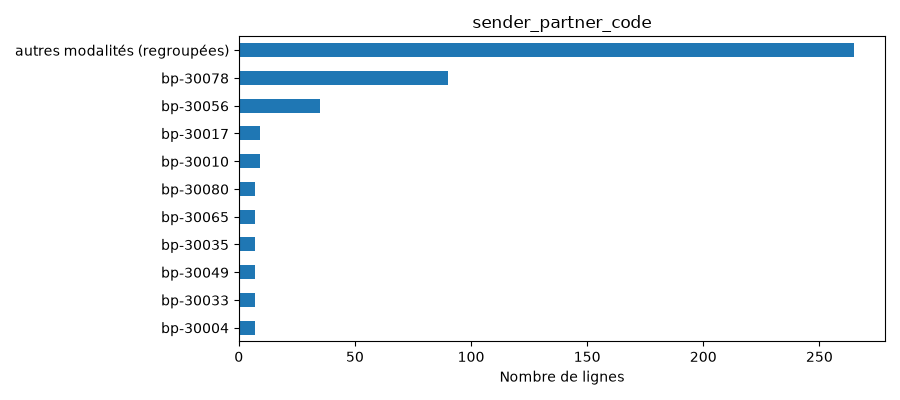

receiver_partner_code


,nombre,pourcentage
receiver_partner_code,,
bp-30021,58,12.89
bp-30078,56,12.44
bp-30056,20,4.44
bp-30033,10,2.22
bp-30046,10,2.22
bp-30079,8,1.78
bp-30020,8,1.78
bp-30009,8,1.78
bp-30006,8,1.78


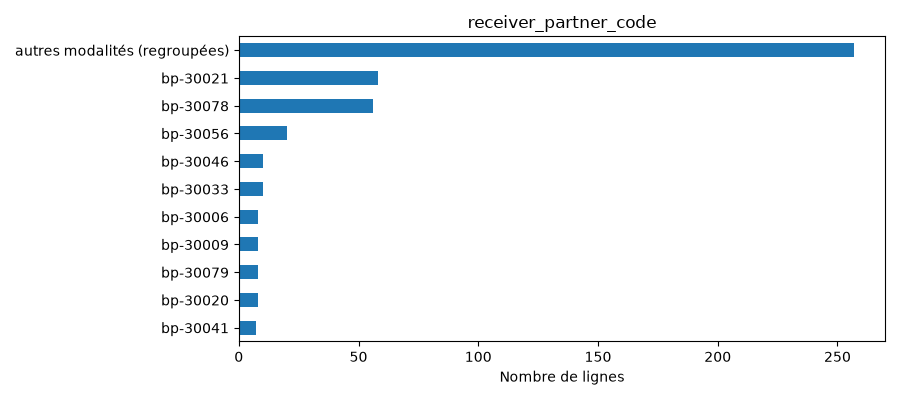

carrier_partner_code


,nombre,pourcentage
carrier_partner_code,,
bp-30047,85,18.89
bp-30042,56,12.44
bp-30055,52,11.56
bp-30015,51,11.33
bp-30025,50,11.11
bp-30078,42,9.33
bp-30060,41,9.11
bp-30020,38,8.44
bp-30031,35,7.78


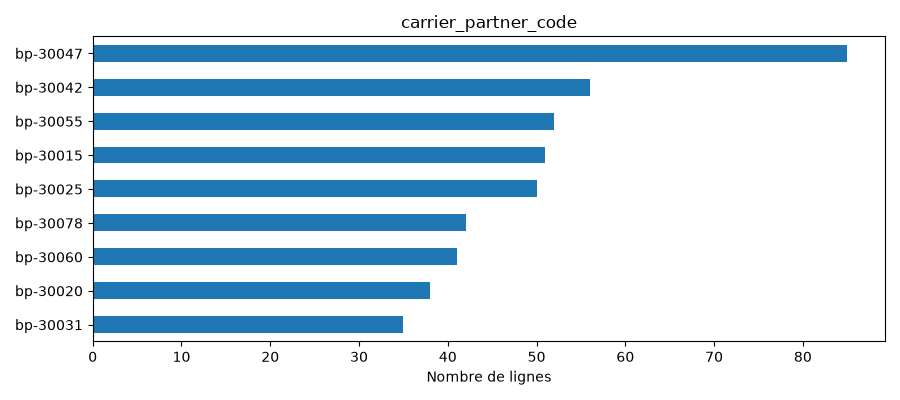

origin_facility_code


,nombre,pourcentage
origin_facility_code,,
fcl-1011,100,22.22
fcl-1019,39,8.67
fcl-1010,37,8.22
fcl-1020,30,6.67
fcl-1030,30,6.67
fcl-1016,23,5.11
fcl-1029,21,4.67
fcl-1007,19,4.22
fcl-1002,13,2.89


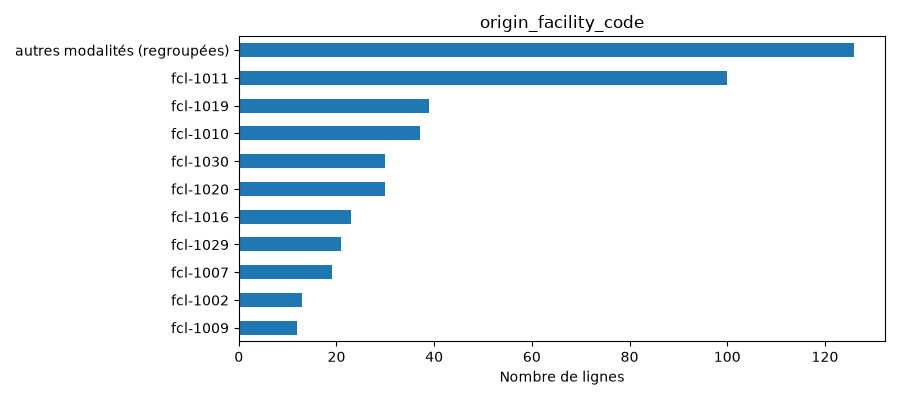

destination_facility_code


,nombre,pourcentage
destination_facility_code,,
fcl-1007,56,12.44
fcl-1010,54,12.00
fcl-1011,50,11.11
fcl-1019,48,10.67
fcl-1029,23,5.11
fcl-1030,22,4.89
fcl-1020,21,4.67
fcl-1016,21,4.67
fcl-1015,19,4.22


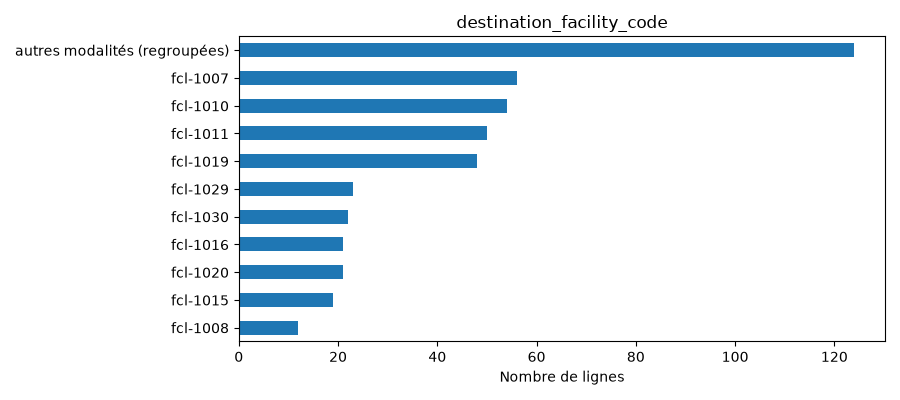

In [15]:
bilans_codes_shipments = decrire_categories(expeditions, [
    "sender_partner_code", "receiver_partner_code", "carrier_partner_code",
    "origin_facility_code", "destination_facility_code"
], limite=10)

item_category


,nombre,pourcentage
item_category,,
biological_sample,52,11.56
medical_consumables,51,11.33
agricultural_product,44,9.78
monitoring_equipment,42,9.33
cold_storage_equipment,34,7.56
laboratory_material,31,6.89
office_supply,27,6.00
refrigeration_service,25,5.56
protective_equipment,25,5.56


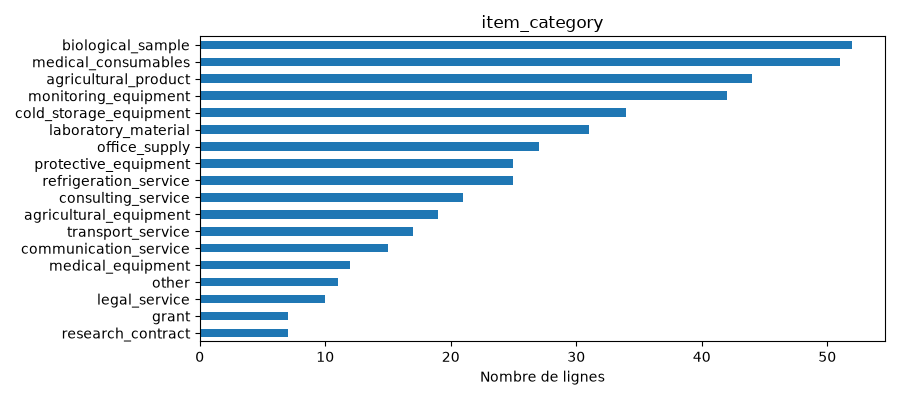

declared_unit


,nombre,pourcentage
declared_unit,,
case,103,22.89
service,88,19.56
unit,76,16.89
sealed_lot,52,11.56
pallet,44,9.78
kit,42,9.33
pack,31,6.89
grant,7,1.56
contract,7,1.56


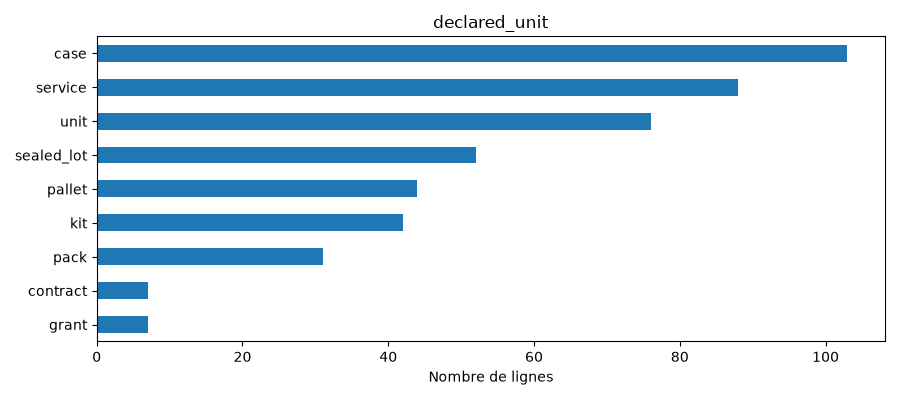

temperature_control_class


,nombre,pourcentage
temperature_control_class,,
ambient,343,76.22
2-8c,103,22.89
frozen,4,0.89


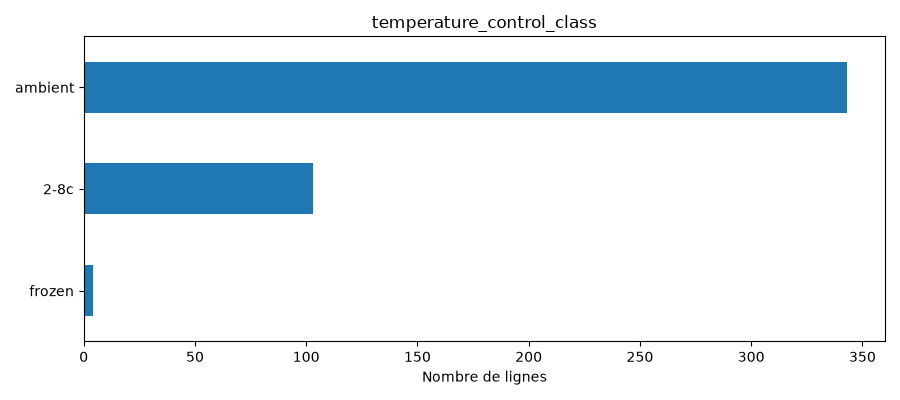

authorization_class


,nombre,pourcentage
authorization_class,,
ordinary,285,63.33
expedited,76,16.89
restricted,60,13.33
emergency,29,6.44


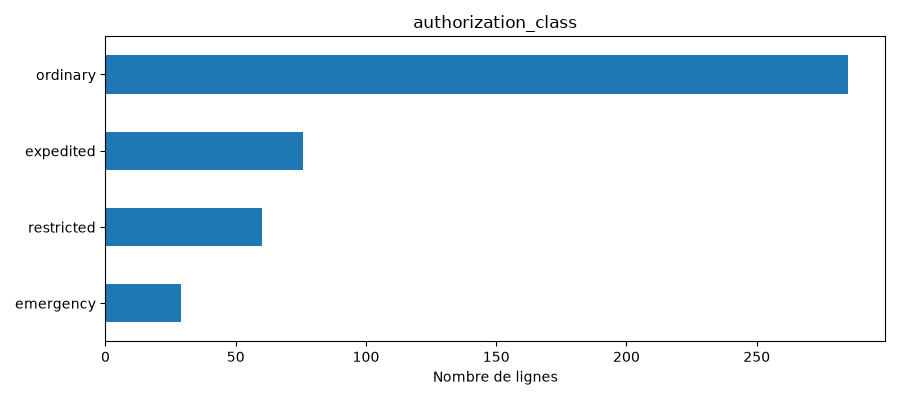

declared_purpose


,nombre,pourcentage
declared_purpose,,
scheduled stock transfer,74,16.44
laboratory delivery,72,16.00
field programme support,72,16.00
customer distribution,64,14.22
facility replenishment,64,14.22
agricultural distribution,60,13.33
temperature-controlled clinical programme delivery,26,5.78
environmental and wildlife reference materials,18,4.00


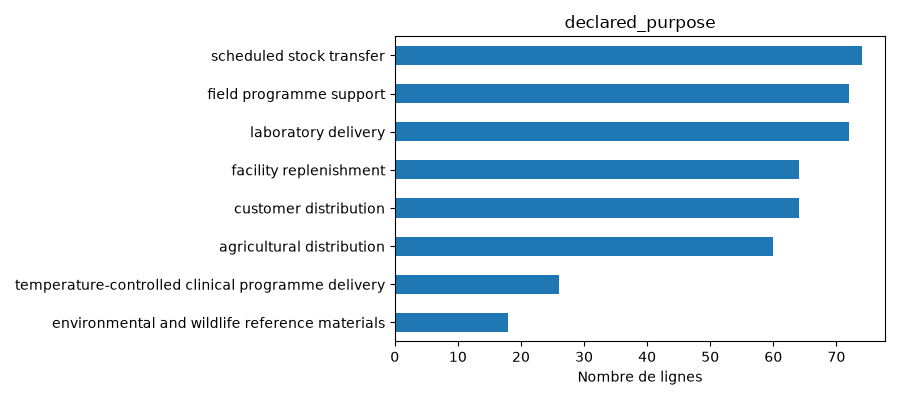

shipment_status


,nombre,pourcentage
shipment_status,,
delivered,385,85.56
delayed,34,7.56
in_transit,17,3.78
returned,14,3.11


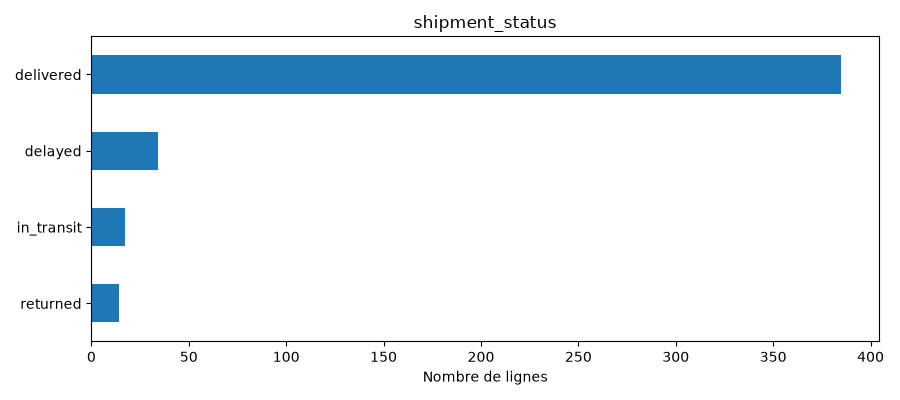

In [16]:
bilans_nominales_shipments = decrire_categories(expeditions, [
    "item_category", "declared_unit", "temperature_control_class",
    "authorization_class", "declared_purpose", "shipment_status"
])

#### Quelles quantités sont habituellement expédiées ?

In [17]:
expeditions = tables_nettoyees["shipments"]

bilan_quantites = expeditions.groupby(
    ["item_category", "declared_unit"]
)["declared_quantity"].describe()

display(bilan_quantites.round(2))

,,count,mean,std,min,25%,50%,75%,max
item_category,declared_unit,,,,,,,,
agricultural_equipment,unit,19.0,11.00,6.62,2.0,5.50,10.0,16.50,21.0
agricultural_product,pallet,44.0,26.25,14.83,1.0,15.00,25.5,37.00,50.0
biological_sample,sealed_lot,52.0,6.54,4.38,1.0,3.00,6.0,8.00,18.0
cold_storage_equipment,unit,34.0,13.15,7.29,2.0,6.25,14.5,17.75,24.0
communication_service,service,15.0,1.00,0.00,1.0,1.00,1.0,1.00,1.0
consulting_service,service,21.0,1.00,0.00,1.0,1.00,1.0,1.00,1.0
grant,grant,7.0,1.00,0.00,1.0,1.00,1.0,1.00,1.0
laboratory_material,pack,31.0,34.94,17.08,3.0,26.00,36.0,49.00,60.0
legal_service,service,10.0,1.00,0.00,1.0,1.00,1.0,1.00,1.0


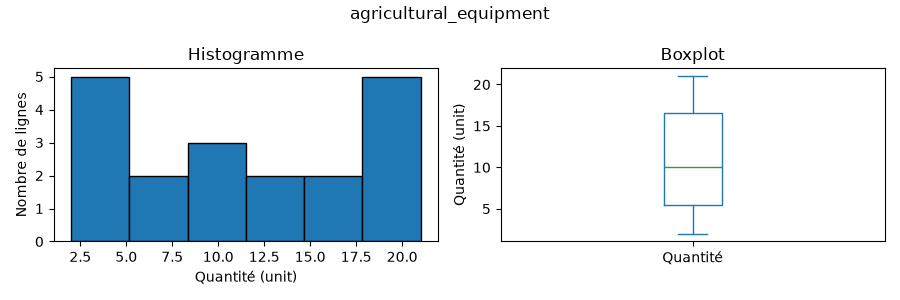

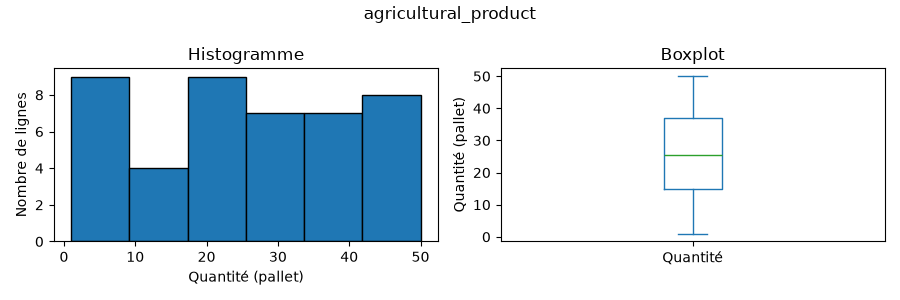

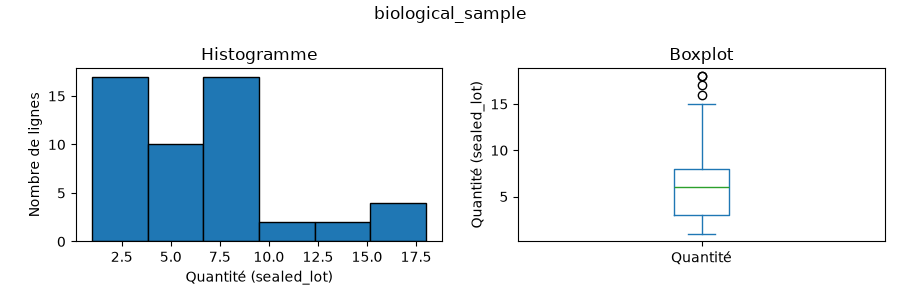

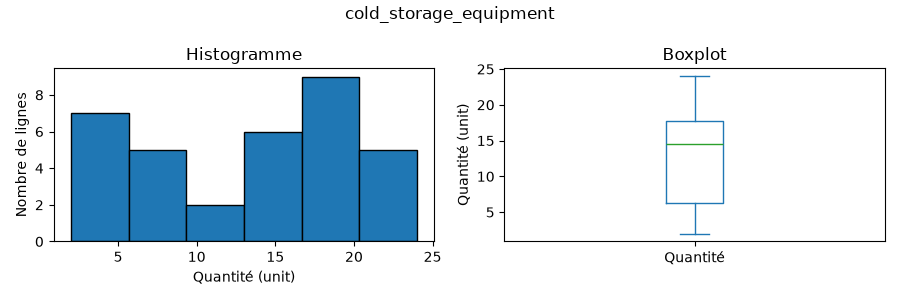

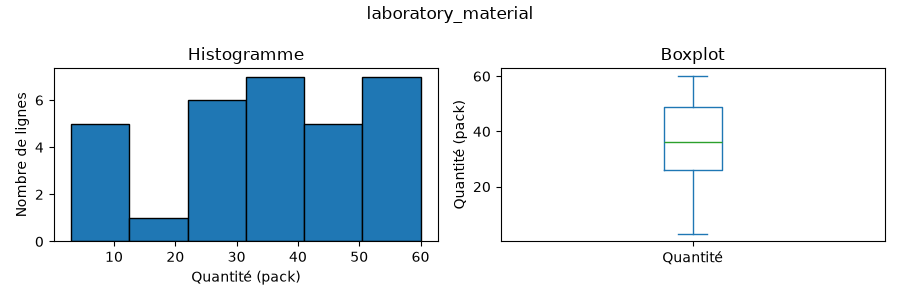

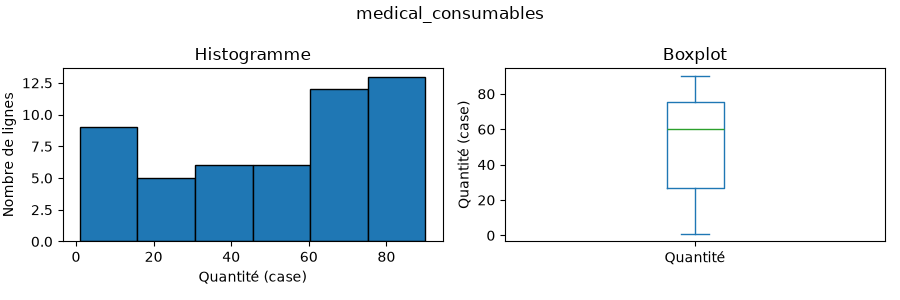

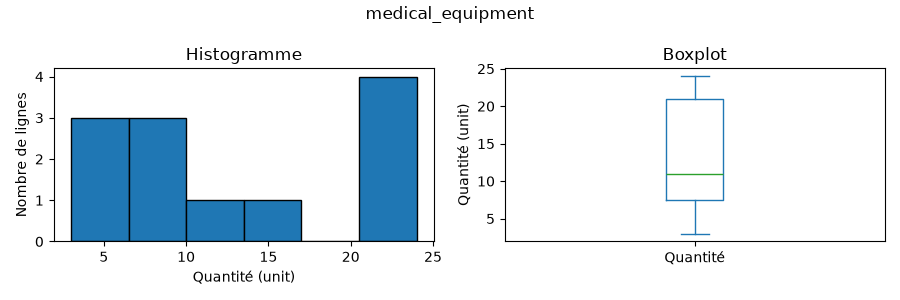

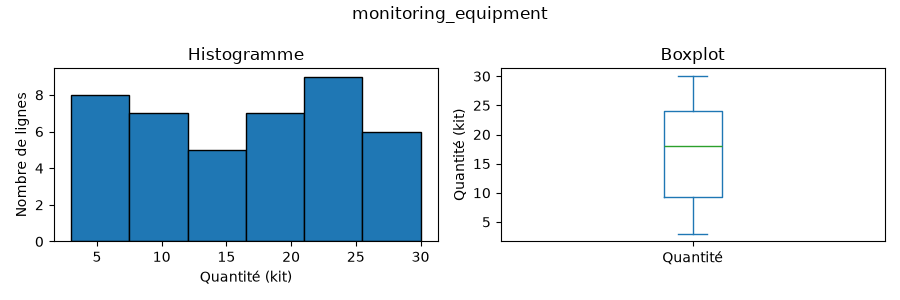

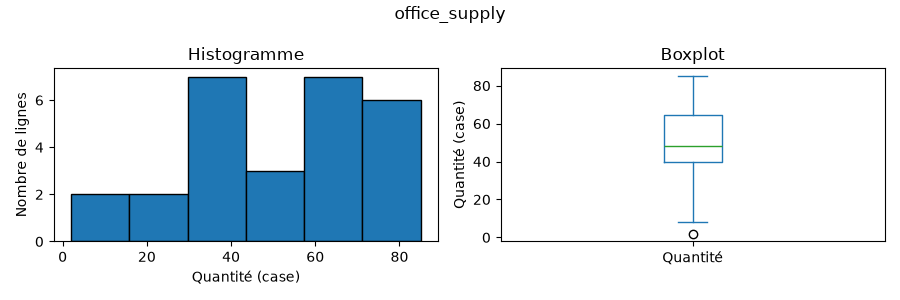

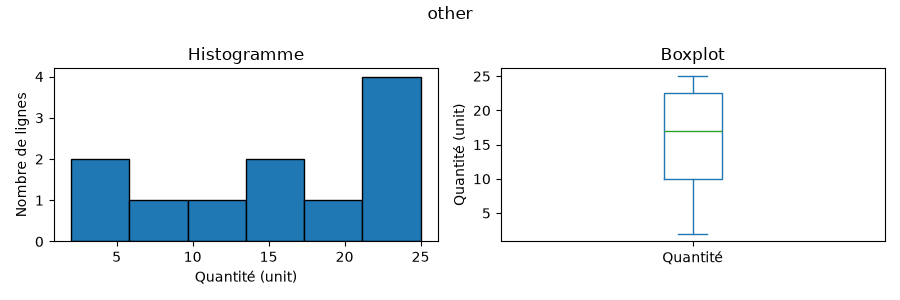

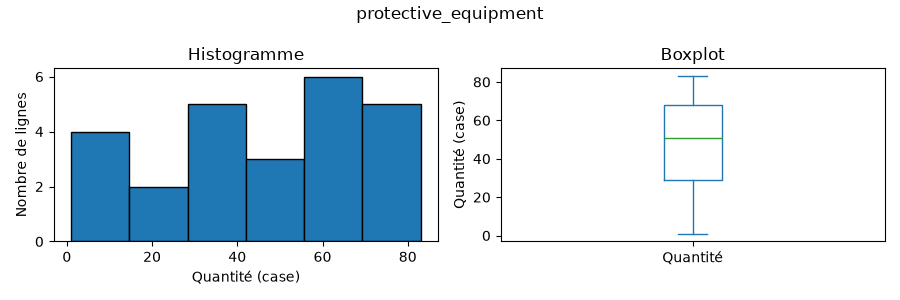

In [18]:
for (categorie, unite), groupe in expeditions.groupby(
    ["item_category", "declared_unit"]
):
    if groupe["declared_quantity"].nunique() <= 1:
        continue  # Les quantités constantes sont déjà décrites dans le tableau.

    fig, axes = plt.subplots(1, 2, figsize=(9, 3))

    groupe["declared_quantity"].plot.hist(bins=6, edgecolor="black", ax=axes[0])
    axes[0].set_xlabel(f"Quantité ({unite})")
    axes[0].set_ylabel("Nombre de lignes")
    axes[0].set_title("Histogramme")

    groupe["declared_quantity"].plot.box(ax=axes[1])
    axes[1].set_ylabel(f"Quantité ({unite})")
    axes[1].set_xticklabels(["Quantité"])
    axes[1].set_title("Boxplot")

    fig.suptitle(categorie)
    plt.tight_layout()
    plt.show()

#### Quelles lignes correspondent aux points éloignés des boxplots ?


In [19]:
lignes_atypiques = []

for (categorie, unite), groupe in expeditions.groupby(
    ["item_category", "declared_unit"]
):
    quantites = groupe["declared_quantity"]
    q1 = quantites.quantile(0.25)
    q3 = quantites.quantile(0.75)
    iqr = q3 - q1

    hors_moustaches = (
        (quantites < q1 - 1.5 * iqr)
        | (quantites > q3 + 1.5 * iqr)
    )
    lignes_atypiques.append(groupe[hors_moustaches])

expeditions_atypiques = pd.concat(lignes_atypiques).copy()
display(expeditions_atypiques[[
    "shipment_number", "item_category", "declared_quantity", "declared_unit"
]])

,shipment_number,item_category,declared_quantity,declared_unit
34,shp-2016-00017,biological_sample,17,sealed_lot
144,shp-2019-00044,biological_sample,18,sealed_lot
294,shp-2022-00060,biological_sample,18,sealed_lot
316,shp-2023-00021,biological_sample,16,sealed_lot
259,shp-2022-00025,office_supply,2,case


In [20]:
noms_sites = tables_nettoyees["erp_facilities"].set_index("facility_code")["facility_name"]
noms_transporteurs = tables_nettoyees["erp_business_partners"].set_index("partner_code")["partner_name"]

expeditions_atypiques["site_depart"] = expeditions_atypiques["origin_facility_code"].map(noms_sites)
expeditions_atypiques["site_arrivee"] = expeditions_atypiques["destination_facility_code"].map(noms_sites)
expeditions_atypiques["transporteur"] = expeditions_atypiques["carrier_partner_code"].map(noms_transporteurs)

display(expeditions_atypiques[[
    "shipment_number", "dispatch_time", "site_depart", "site_arrivee", "transporteur"
]])
display(expeditions_atypiques[[
    "shipment_number", "temperature_control_class", "authorization_class",
    "declared_purpose", "shipment_status"
]])

# Comparer la température des cas retenus à celle de toute leur catégorie.
print("Températures des 52 lignes d'échantillons biologiques :")
display(expeditions.loc[
    expeditions["item_category"].eq("biological_sample"), "temperature_control_class"
].value_counts(dropna=False))

,shipment_number,dispatch_time,site_depart,site_arrivee,transporteur
34,shp-2016-00017,2016-12-20 08:00:00,lumen safety equipment store,eastgate clinical receiving unit,amber storage and transit
144,shp-2019-00044,2019-11-22 12:00:00,asterion central clinical campus,kintara emergency logistics depot,northstar cold chain services
294,shp-2022-00060,2022-12-02 10:00:00,meridian valenne headquarters,asterion avelora executive clinic,tembara port services
316,shp-2023-00021,2023-04-13 06:00:00,valenne laboratory materials store,asterion central clinical campus,nacre air cargo
259,shp-2022-00025,2022-02-23 08:00:00,asterion central clinical campus,kintara field equipment depot,north quay biomedical storage


,shipment_number,temperature_control_class,authorization_class,declared_purpose,shipment_status
34,shp-2016-00017,2-8c,emergency,facility replenishment,delivered
144,shp-2019-00044,2-8c,ordinary,facility replenishment,delivered
294,shp-2022-00060,2-8c,restricted,scheduled stock transfer,delivered
316,shp-2023-00021,2-8c,ordinary,laboratory delivery,delivered
259,shp-2022-00025,ambient,ordinary,laboratory delivery,delivered


Températures des 52 lignes d'échantillons biologiques :


temperature_control_class
2-8c    52
Name: count, dtype: int64

#### Construire et décrire une durée à partir des horaires

Durées disponibles : 433
Durées négatives : 0


count    433.00
mean      49.92
std       26.35
min        6.00
25%       26.00
50%       49.00
75%       74.00
max       95.00
Name: duree_heures, dtype: float64

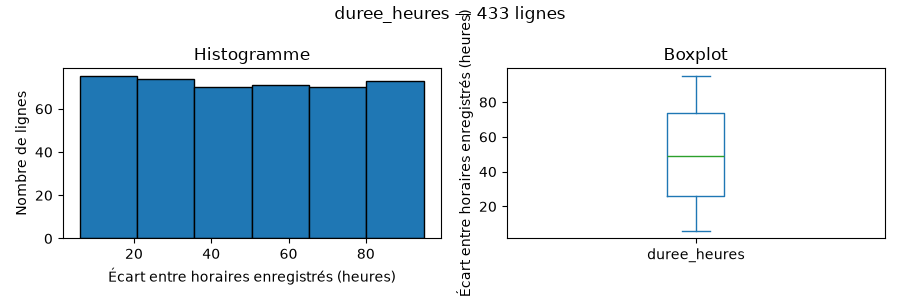

In [21]:
expeditions_durees = expeditions.copy()
expeditions_durees["duree_heures"] = (
    expeditions_durees["arrival_time"] - expeditions_durees["dispatch_time"]
).dt.total_seconds() / 3600

print("Durées disponibles :", expeditions_durees["duree_heures"].notna().sum())
print("Durées négatives :", expeditions_durees["duree_heures"].lt(0).sum())
display(expeditions_durees["duree_heures"].describe().round(2))
tracer_distribution(
    expeditions_durees.dropna(subset=["duree_heures"]),
    "duree_heures", "Écart entre horaires enregistrés (heures)"
)


####  La quantité expédiée est-elle associée à la durée enregistrée ?

In [22]:
resultats_correlations = []

for (categorie, unite), groupe in expeditions_durees.groupby(
    ["item_category", "declared_unit"]
):
    paires = groupe[["declared_quantity", "duree_heures"]].dropna()
    ligne = {"categorie": categorie, "unite": unite, "n": len(paires),
             "Pearson": float("nan"), "Spearman": float("nan")}

    if len(paires) < 3:
        ligne["etat"] = "moins de 3 paires"
    elif paires.nunique().min() < 2:
        ligne["etat"] = "variable constante"
    else:
        ligne["etat"] = "calculé"
        ligne["Pearson"] = paires["declared_quantity"].corr(paires["duree_heures"])
        rangs = paires.rank()
        ligne["Spearman"] = rangs["declared_quantity"].corr(rangs["duree_heures"])

    resultats_correlations.append(ligne)

correlations_shipments = pd.DataFrame(resultats_correlations).sort_values(
    "n", ascending=False, kind="stable"
).reset_index(drop=True)
display(correlations_shipments.round(3))

,categorie,unite,n,Pearson,Spearman,etat
0,biological_sample,sealed_lot,51,-0.321,-0.322,calculé
1,medical_consumables,case,49,0.056,0.094,calculé
2,agricultural_product,pallet,44,0.245,0.245,calculé
3,monitoring_equipment,kit,41,0.046,0.039,calculé
4,cold_storage_equipment,unit,33,-0.221,-0.266,calculé
5,laboratory_material,pack,29,-0.042,-0.115,calculé
6,office_supply,case,25,0.064,0.141,calculé
7,refrigeration_service,service,24,NaN,NaN,variable constante
8,protective_equipment,case,22,-0.246,-0.288,calculé
9,consulting_service,service,20,NaN,NaN,variable constante


In [23]:
paires_biologiques = expeditions_durees[
    expeditions_durees["item_category"].eq("biological_sample")
    & expeditions_durees["declared_unit"].eq("sealed_lot")
][["declared_quantity", "duree_heures"]].dropna()

print("Pearson — échantillons biologiques")
display(paires_biologiques.corr(method="pearson").round(3))
print("Spearman — échantillons biologiques")
display(paires_biologiques.rank().corr(method="pearson").round(3))

Pearson — échantillons biologiques


,declared_quantity,duree_heures
declared_quantity,1.000,-0.321
duree_heures,-0.321,1.000


Spearman — échantillons biologiques


,declared_quantity,duree_heures
declared_quantity,1.000,-0.322
duree_heures,-0.322,1.000


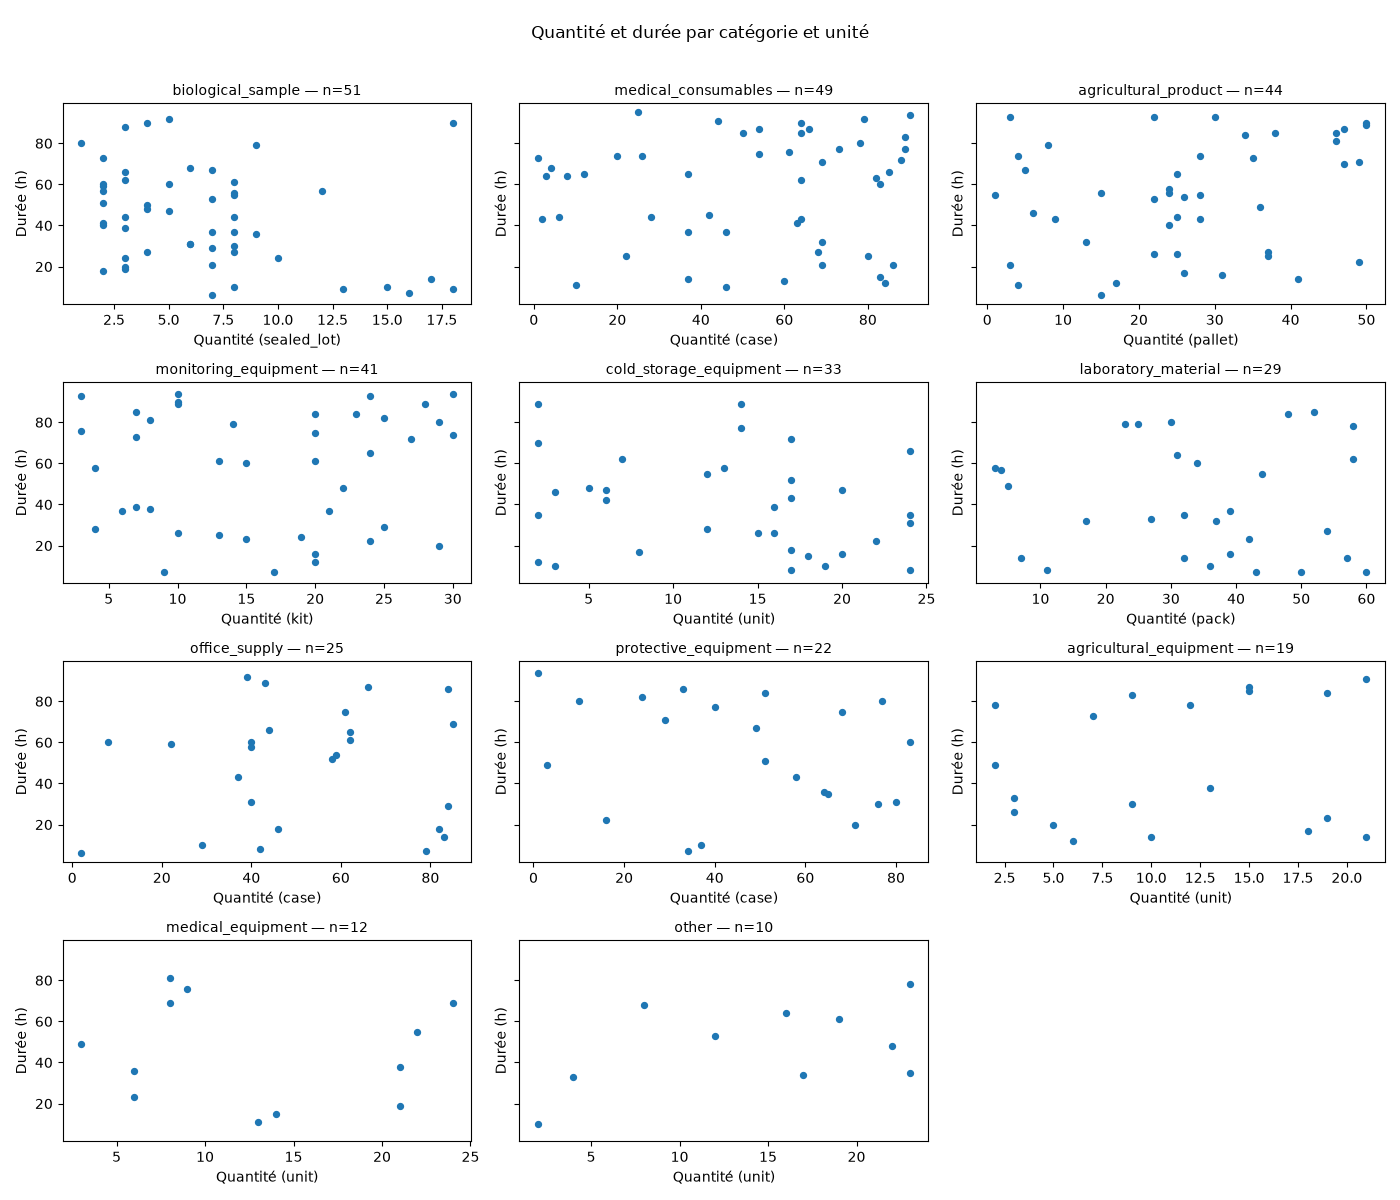

In [24]:
groupes_calcules = correlations_shipments[
    correlations_shipments["etat"].eq("calculé")
]
fig, axes = plt.subplots(4, 3, figsize=(14, 12), sharey=True)

# Un panneau par groupe ; la dernière case restera vide.
for ax, (_, ligne) in zip(axes.flat, groupes_calcules.iterrows()):
    groupe = expeditions_durees[
        expeditions_durees["item_category"].eq(ligne["categorie"])
        & expeditions_durees["declared_unit"].eq(ligne["unite"])
    ][["declared_quantity", "duree_heures"]].dropna()
    ax.scatter(groupe["declared_quantity"], groupe["duree_heures"], s=18)
    ax.set_title(f"{ligne['categorie']} — n={len(groupe)}", fontsize=10)
    ax.set_xlabel(f"Quantité ({ligne['unite']})")
    ax.set_ylabel("Durée (h)")

for ax in axes.flat:
    if not ax.has_data():
        ax.set_visible(False)

fig.suptitle("Quantité et durée par catégorie et unité")
plt.tight_layout(rect=[0, 0, 1, 0.97])
plt.show()

**Bilan provisoire de `shipments` — CM1**

- Nous conservons 450 lignes après nettoyage. Les 16 champs ont été décrits ; les 17 arrivées absentes concernent des expéditions en transit.
- Les distributions des catégories et des codes identifient des acteurs et sites fréquents. Par exemple, Meridian Biologistics est l'expéditeur le plus fréquent (90 lignes) et `fcl-1011` le site de départ le plus fréquent (100 lignes). Ces comptages ne mesurent pas les volumes physiques transportés.
- Quatre quantités élevées d'échantillons biologiques et une faible quantité de fournitures de bureau sont documentées et conservées. Leur caractère atypique n'établit pas une erreur ou une activité suspecte.
- Les 433 durées calculables permettent une exploration quantité–durée par catégorie et unité. Les résultats diffèrent entre groupes ; les trajets et acteurs restent des éléments de contexte à examiner.

**Pistes pour la suite :** comparer les acteurs et sites fréquents avec ceux des commandes et des stocks, puis replacer les lignes atypiques dans ces autres informations. Le narratif n'est pas encore établi ; cette étape fournit des constats vérifiables et des questions à poursuivre.


### Décrire les commandes (`purchase_order_lines`)

Après nettoyage, cette table contient **650 lignes de commande**. Nous centrons cette première analyse sur les quantités commandées et les catégories utiles pour comprendre les opérations.

Nous réutilisons trois fonctions simples : décrire une variable numérique par groupes, tracer un histogramme et un boxplot, puis compter les catégories. Pour les autres fichiers, nous pourrons adapter les colonnes et les groupes en gardant cette même démarche du CM1.

####  Quelles quantités sont commandées ?



In [25]:
commandes = tables_nettoyees["purchase_order_lines"]

bilan_quantites_commandes = decrire_numerique(
    commandes, "ordered_quantity", ["item_category", "ordered_unit"]
)

,,count,mean,std,min,25%,50%,75%,max
item_category,ordered_unit,,,,,,,,
agricultural_equipment,unit,23.0,13.22,7.89,1.0,6.00,15.0,21.00,24.0
agricultural_product,pallet,53.0,27.53,13.72,2.0,16.00,27.0,38.00,50.0
biological_sample,sealed_lot,42.0,8.40,4.48,1.0,5.00,7.5,11.00,18.0
cold_storage_equipment,unit,54.0,13.35,6.77,3.0,7.00,14.0,19.00,25.0
communication_service,service,17.0,1.00,0.00,1.0,1.00,1.0,1.00,1.0
consulting_service,service,25.0,1.00,0.00,1.0,1.00,1.0,1.00,1.0
grant,grant,11.0,1.00,0.00,1.0,1.00,1.0,1.00,1.0
laboratory_material,pack,44.0,30.59,17.85,3.0,16.25,32.5,43.50,60.0
legal_service,service,22.0,1.00,0.00,1.0,1.00,1.0,1.00,1.0


**Exemple graphique.** Nous détaillons les consommables médicaux en caisses, le groupe le plus fourni avec 79 lignes. Le tableau précédent couvre tous les groupes ; cet exemple permet de lire la distribution sans multiplier les graphiques.

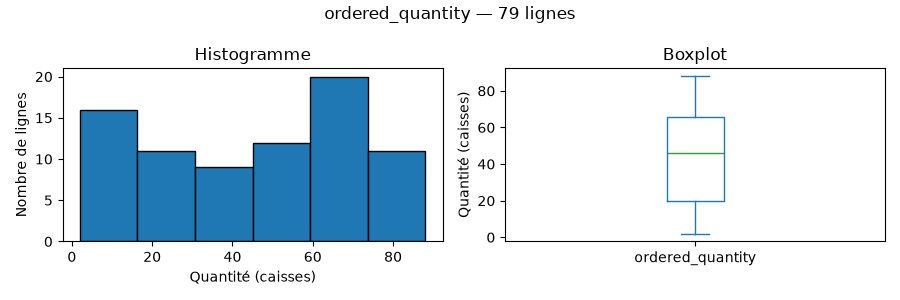

In [26]:
quantites_exemple = commandes[
    commandes["item_category"].eq("medical_consumables")
    & commandes["ordered_unit"].eq("case")
]
tracer_distribution(quantites_exemple, "ordered_quantity", "Quantité (caisses)")

**Constats.** Pour les consommables médicaux en caisses, la moyenne est de 44,28 et l'écart-type de 25,90. La médiane est de 46, avec des quantités allant de 2 à 88 caisses. Les quantités sont donc dispersées au sein de ce groupe. Son boxplot ne signale pas de point au-delà des moustaches selon la règle utilisée ; cela ne suffit pas à établir que toutes ces commandes sont cohérentes avec leur contexte.

####  Quels statuts, autorisations et centres de coût sont fréquents ?

Nous comptons les lignes de chaque catégorie et leur pourcentage, puis nous observons les diagrammes en barres. Une valeur absente est affichée comme `non_renseigne` pour rester visible dans les comptages.

order_status


,nombre,pourcentage
order_status,,
completed,610,93.85
delayed,18,2.77
pending,14,2.15
cancelled,8,1.23


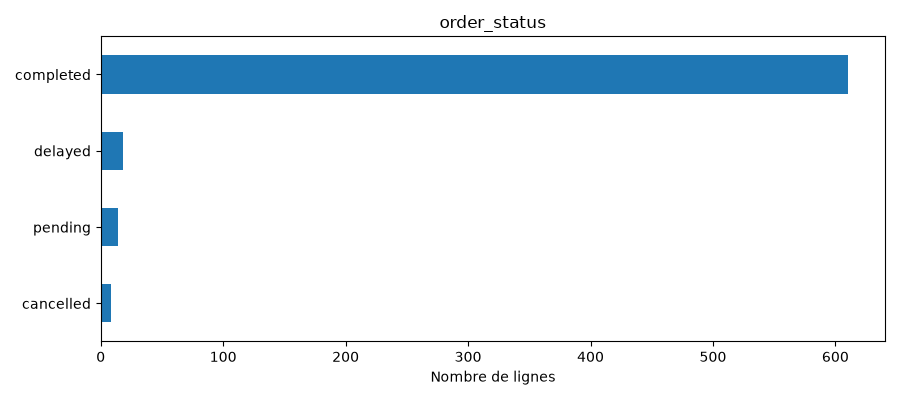

authorization_class


,nombre,pourcentage
authorization_class,,
ordinary,404,62.15
expedited,123,18.92
restricted,83,12.77
emergency,40,6.15


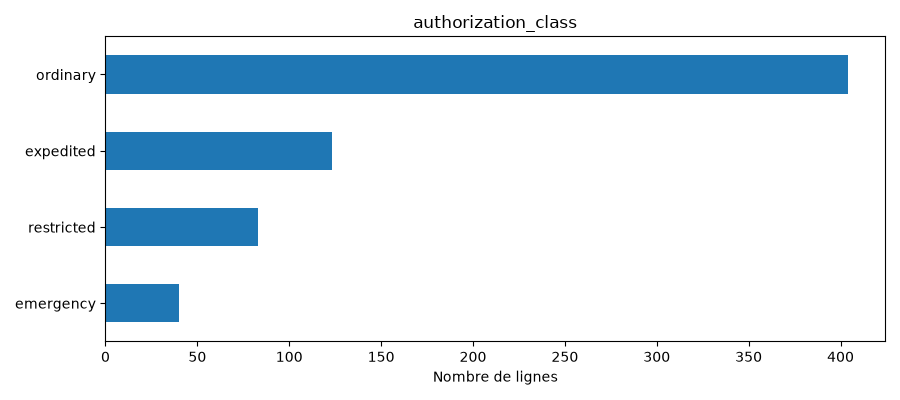

declared_cost_center


,nombre,pourcentage
declared_cost_center,,
field programmes,98,15.08
clinical services,93,14.31
research services,90,13.85
agricultural distribution,87,13.38
general operations,84,12.92
facilities,81,12.46
cold chain,70,10.77
clinical programmes,26,4.00
field operations,18,2.77


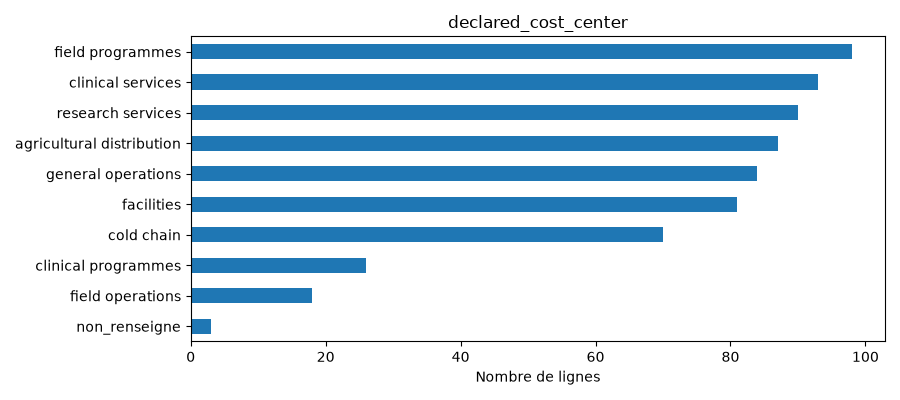

In [27]:
bilans_categories_commandes = decrire_categories(commandes, [
    "order_status", "authorization_class", "declared_cost_center"
])

**Constats et pistes.** 610 lignes sont au statut `completed` (93,85 %). Les autres statuts sont `delayed` : 18 lignes (2,77 %), `pending` : 14 (2,15 %) et `cancelled` : 8 (1,23 %). Les autorisations ordinaires sont les plus fréquentes, avec 404 lignes (62,15 %). Trois centres de coût restent non renseignés (0,46 %).

Le statut d'une commande ne remplace pas l'examen des réceptions. La question à poursuivre est simple : **les quantités reçues correspondent-elles aux quantités commandées ?** Il faudra rapprocher les lignes de commande des réceptions, vérifier les unités et examiner les écarts dans leur contexte.

#### Peut-on rapprocher les lignes et comparer leurs unités ?

`merge()` ajoute à chaque réception les informations de sa ligne de commande. `how="left"` conserve toutes les réceptions et `validate="many_to_one"` vérifie qu'une réception ne peut pas correspondre à plusieurs lignes de commande. Plusieurs réceptions d'une même ligne restent possibles.

In [25]:
commandes = tables_nettoyees["purchase_order_lines"]
receptions = tables_nettoyees["goods_receipts"]
cles = ["purchase_order_number", "purchase_order_line"]

comparaison = receptions.merge(
    commandes[cles + ["item_category", "ordered_quantity", "ordered_unit", "order_status"]],
    on=cles,
    how="left",
    validate="many_to_one",
    indicator=True
)

sans_commande = comparaison["_merge"].eq("left_only").sum()
unites_differentes = (
    comparaison["_merge"].eq("both")
    & comparaison["received_unit"].ne(comparaison["ordered_unit"])
).sum()

print("Réceptions sans ligne de commande :", sans_commande)
print("Réceptions avec une unité différente :", unites_differentes)

if sans_commande > 0 or unites_differentes > 0:
    raise ValueError("Vérifier les références et les unités avant de comparer les quantités.")

Réceptions sans ligne de commande : 0
Réceptions avec une unité différente : 0


**Résultat.** Les 610 réceptions correspondent à une ligne de commande et utilisent la même unité que celle-ci. Nous pouvons donc comparer leurs quantités. Ce contrôle ne suffit pas à garantir la cohérence de tous les autres champs.

#### 9.2. Quelle quantité a été reçue pour chaque ligne de commande ?


In [26]:
totaux_receptions = receptions.groupby(cles, as_index=False).agg(
    quantite_recue=("received_quantity", "sum"),
    nombre_receptions=("receipt_number", "size")
)

bilan_commandes_receptions = commandes[
    cles + ["item_category", "ordered_quantity", "ordered_unit", "order_status"]
].merge(
    totaux_receptions,
    on=cles,
    how="left",
    validate="one_to_one"
)

bilan_commandes_receptions["nombre_receptions"] = (
    bilan_commandes_receptions["nombre_receptions"].fillna(0).astype(int)
)
bilan_commandes_receptions["quantite_recue"] = (
    bilan_commandes_receptions["quantite_recue"].fillna(0)
)
bilan_commandes_receptions["ecart"] = (
    bilan_commandes_receptions["quantite_recue"]
    - bilan_commandes_receptions["ordered_quantity"]
).round(2)

In [27]:
bilan_commandes_receptions["situation"] = "quantité égale"
bilan_commandes_receptions.loc[
    bilan_commandes_receptions["ecart"] < 0, "situation"
] = "quantité inférieure"
bilan_commandes_receptions.loc[
    bilan_commandes_receptions["ecart"] > 0, "situation"
] = "quantité supérieure"
bilan_commandes_receptions.loc[
    bilan_commandes_receptions["nombre_receptions"].eq(0), "situation"
] = "sans réception enregistrée"

tableau_receptions = pd.crosstab(
    bilan_commandes_receptions["order_status"],
    bilan_commandes_receptions["situation"]
)
display(tableau_receptions)

situation,quantité inférieure,quantité égale,sans réception enregistrée
order_status,,,
cancelled,0,0,8
completed,65,545,0
delayed,0,0,18
pending,0,0,14


In [28]:
ecarts_avec_reception = bilan_commandes_receptions[
    bilan_commandes_receptions["nombre_receptions"].gt(0)
    & bilan_commandes_receptions["ecart"].lt(0)
]

# Cinq premières lignes, dans l'ordre du fichier, pour comprendre les écarts.
display(ecarts_avec_reception[
    cles + ["item_category", "ordered_quantity", "quantite_recue",
            "ordered_unit", "ecart", "order_status"]
].head(5))

,purchase_order_number,purchase_order_line,item_category,ordered_quantity,quantite_recue,ordered_unit,ecart,order_status
1,po-2015-00001,1,transport_service,1,0.90,service,-0.10,completed
28,po-2016-00002,1,medical_consumables,61,56.41,case,-4.59,completed
33,po-2016-00007,1,refrigeration_service,1,0.89,service,-0.11,completed
41,po-2016-00015,1,medical_consumables,3,2.44,case,-0.56,completed
54,po-2016-00028,1,transport_service,1,0.88,service,-0.12,completed


**Un exemple concret.** Pour la commande `po-2016-00002`, ligne 1, la quantité commandée est de **61 caisses** et la quantité reçue enregistrée de **56,41 caisses**. L'écart vaut donc `56,41 − 61 = −4,59 caisses`, alors que la commande est au statut `completed`.

#### Décrire les quantités reçues

Nous réutilisons le résumé numérique du CM1 en séparant les catégories et les unités. Les réceptions sont comptées telles qu'elles sont enregistrées, y compris celles en attente pour qualité.

In [29]:
bilan_receptions = decrire_numerique(
    comparaison, "received_quantity", ["item_category", "received_unit"]
)

,,count,mean,std,min,25%,50%,75%,max
item_category,received_unit,,,,,,,,
agricultural_equipment,unit,23.0,13.17,7.90,1.00,6.00,15.00,21.00,24.0
agricultural_product,pallet,46.0,27.70,13.72,2.00,16.75,26.50,37.75,50.0
biological_sample,sealed_lot,39.0,8.32,4.59,1.00,4.69,8.00,11.00,18.0
cold_storage_equipment,unit,51.0,13.16,6.70,2.56,7.00,14.00,18.50,25.0
communication_service,service,17.0,0.98,0.06,0.78,1.00,1.00,1.00,1.0
consulting_service,service,25.0,0.99,0.05,0.82,1.00,1.00,1.00,1.0
grant,grant,10.0,0.99,0.03,0.90,1.00,1.00,1.00,1.0
laboratory_material,pack,41.0,29.58,16.90,3.00,17.00,31.67,41.00,60.0
legal_service,service,22.0,0.99,0.02,0.93,1.00,1.00,1.00,1.0


Les quantités reçues sont décrites par catégorie d'article et unité, comme les quantités commandées et expédiées. Certaines quantités de services, contrats et subventions sont inférieures à 1. Nous les conservons : leur interprétation dépend du sens de ces enregistrements. Une catégorie peut encore réunir plusieurs articles différents.

#### Quels statuts d'inspection et de réception sont fréquents ?

Nous conservons les comptages déjà réalisés. Ils décrivent la situation des réceptions ; la présence d'une quantité reçue ne signifie pas à elle seule que le stock est immédiatement disponible.

,nombre,pourcentage
inspection_status,,
accepted,505,82.79
conditional,67,10.98
held,34,5.57
non_renseigne,4,0.66


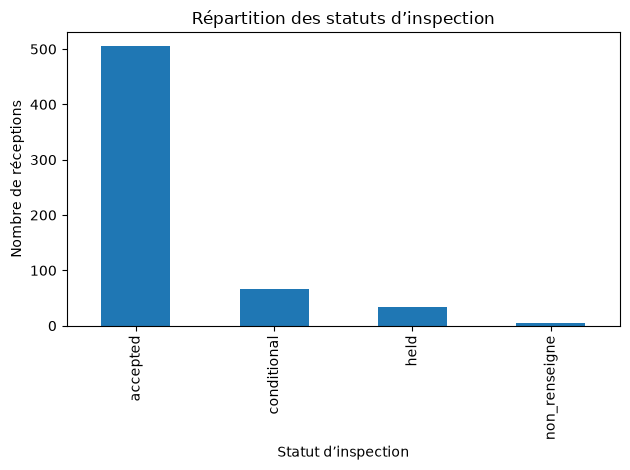

In [30]:
effectifs = receptions["inspection_status"].fillna("non_renseigne").value_counts()

display(pd.DataFrame({
    "nombre": effectifs,
    "pourcentage": (effectifs / len(receptions) * 100).round(2)
}))

effectifs.plot.bar()
plt.title("Répartition des statuts d’inspection")
plt.xlabel("Statut d’inspection")
plt.ylabel("Nombre de réceptions")
plt.tight_layout()
plt.show()

Les inspections sont majoritairement acceptées (82,79 %). Les statuts conditional représentent 10,98 % des réceptions et held 5,57 %. Quatre réceptions (0,66 %) n’ont pas de statut renseigné. Ces catégories sont conservées : un statut conditionnel ou en attente ne constitue pas une erreur de données.

In [31]:
display(
    receptions[receptions["inspection_status"].isna()][[
        "receipt_number",
        "receipt_date",
        "received_quantity",
        "received_unit",
        "receipt_status"
    ]]
)

,receipt_number,receipt_date,received_quantity,received_unit,receipt_status
76,rcv-2017-00077,2017-12-31,26.00,pallet,posted
364,rcv-2022-00365,2022-11-10,72.00,case,posted
432,rcv-2023-00433,2023-05-02,0.82,service,posted
603,rcv-2025-00604,2025-06-13,37.00,pack,posted


Les quatre statuts d’inspection manquants concernent des réceptions comptabilisées (posted), de dates et d’unités différentes. Les autres champs examinés ne permettent pas de reconstituer l’information. Nous conservons donc ces valeurs manquantes et les lignes correspondantes.

In [32]:
effectifs = receptions["receipt_status"].value_counts(dropna=False)

display(pd.DataFrame({
    "nombre": effectifs,
    "pourcentage": (effectifs / len(receptions) * 100).round(2)
}))

,nombre,pourcentage
receipt_status,,
posted,576,94.43
quality_hold,34,5.57


Les réceptions sont majoritairement comptabilisées (94,43 %). Les réceptions en attente pour qualité représentent 5,57 %.

### Examiner les relations entre variables de stock (`inventory_month_end`)

Nous changeons maintenant de fichier. La suite porte sur les corrélations entre les variables de stock

In [33]:
stocks = tables_nettoyees["inventory_month_end"]

stocks_medicaux = stocks[
    (stocks["item_category"] == "medical_consumables")
    & (stocks["unit"] == "case")
]

variables = [
    "received_quantity",
    "outgoing_quantity",
    "documented_internal_use",
    "documented_waste",
    "closing_stock"
]

print("Pearson")
display(stocks_medicaux[variables].corr(method="pearson").round(2))

print("Spearman")
display(stocks_medicaux[variables].corr(method="spearman").round(2))

Pearson


,received_quantity,outgoing_quantity,documented_internal_use,documented_waste,closing_stock
received_quantity,1.00,-0.09,0.33,0.26,0.60
outgoing_quantity,-0.09,1.00,0.05,-0.01,-0.03
documented_internal_use,0.33,0.05,1.00,0.57,0.73
documented_waste,0.26,-0.01,0.57,1.00,0.73
closing_stock,0.60,-0.03,0.73,0.73,1.00


Spearman


,received_quantity,outgoing_quantity,documented_internal_use,documented_waste,closing_stock
received_quantity,1.00,-0.08,0.17,0.11,0.34
outgoing_quantity,-0.08,1.00,0.07,0.13,-0.09
documented_internal_use,0.17,0.07,1.00,0.48,0.63
documented_waste,0.11,0.13,0.48,1.00,0.66
closing_stock,0.34,-0.09,0.63,0.66,1.00


Les stocks finaux élevés tendent à être associés à davantage d’usage interne et de déchets. Cette association apparaît avec Pearson et Spearman. Elle peut notamment refléter des différences de taille ou d’activité entre sites. La relation entre réceptions et stock final est moins marquée avec Spearman ; sa forme et l’influence éventuelle de grandes valeurs doivent être examinées graphiquement. Ces corrélations ne démontrent pas de causalité.

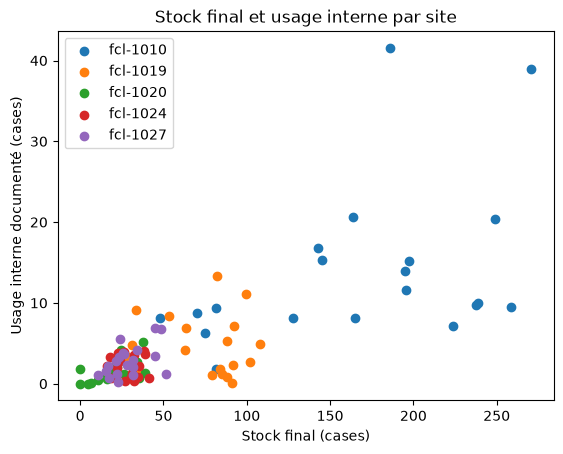

In [34]:
fig, ax = plt.subplots()

for site, groupe in stocks_medicaux.groupby("facility_code"):
    ax.scatter(
        groupe["closing_stock"],
        groupe["documented_internal_use"],
        label=site
    )

ax.set_xlabel("Stock final (cases)")
ax.set_ylabel("Usage interne documenté (cases)")
ax.set_title("Stock final et usage interne par site")
ax.legend()
plt.show()

Nous visualisons la relation entre stock final et usage interne, car elle présente des coefficients de corrélation élevés avec Pearson et Spearman. La coloration par site permet d’examiner le rôle des différences entre établissements.

La coloration par site montre que la corrélation globale reflète en partie des différences entre établissements. Le site fcl-1010 se distingue par des niveaux élevés de stock final et d’usage interne. On ne peut donc pas déduire de la corrélation globale que cette relation est identique au sein de chaque site. Ces niveaux élevés ne constituent pas, à eux seuls, des anomalies.

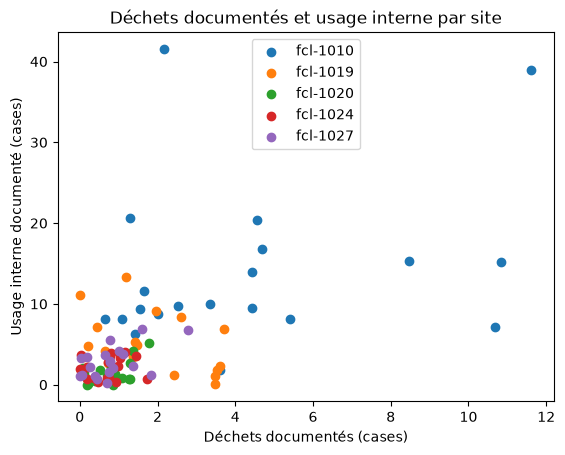

In [35]:
fig, ax = plt.subplots()

for site, groupe in stocks_medicaux.groupby("facility_code"):
    ax.scatter(
        groupe["documented_waste"],
        groupe["documented_internal_use"],
        label=site
    )

ax.set_xlabel("Déchets documentés (cases)")
ax.set_ylabel("Usage interne documenté (cases)")
ax.set_title("Déchets documentés et usage interne par site")
ax.legend()
plt.show()

Les déchets documentés et l’usage interne présentent une association positive, avec une dispersion importante. Les différences de niveaux entre sites contribuent vraisemblablement à cette association. Le graphique ne permet pas d’établir qu’un usage interne élevé provoque davantage de déchets, ni d’identifier une anomalie à lui seul.

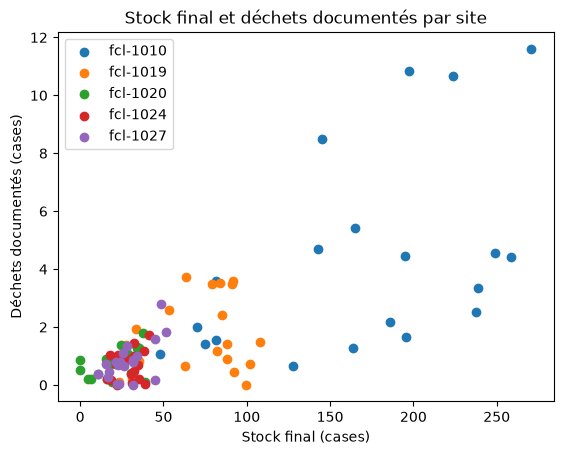

In [36]:
fig, ax = plt.subplots()

for site, groupe in stocks_medicaux.groupby("facility_code"):
    ax.scatter(
        groupe["closing_stock"],
        groupe["documented_waste"],
        label=site
    )

ax.set_xlabel("Stock final (cases)")
ax.set_ylabel("Déchets documentés (cases)")
ax.set_title("Stock final et déchets documentés par site")
ax.legend()
plt.show()

Une association positive apparaît entre stock final et déchets documentés. La coloration montre que les différences entre sites contribuent à cette relation. Les quantités de déchets seules ne permettent pas de comparer leur efficacité : un établissement plus actif peut produire davantage de déchets en volume

Les corrélations et les graphiques montrent que les stocks finaux élevés sont associés à davantage d’usage interne et de déchets. Le site fcl-1010 présente les niveaux les plus élevés sur ces variables. Ces différences peuvent refléter des volumes d’activité différents et ne suffisent pas à identifier une anomalie. Nous poursuivons donc avec une comparaison des profils des sites.

In [37]:
profils_sites = stocks_medicaux.groupby("facility_code")[variables].mean()

display(profils_sites.round(2))

,received_quantity,outgoing_quantity,documented_internal_use,documented_waste,closing_stock
facility_code,,,,,
fcl-1010,33.23,2.94,14.07,4.32,167.62
fcl-1019,9.06,1.70,4.67,1.71,71.07
fcl-1020,3.25,3.99,1.46,0.76,21.09
fcl-1024,3.86,2.02,2.16,0.68,28.41
fcl-1027,3.76,1.81,2.83,0.82,28.59


- fcl-1010 présente les moyennes les plus élevées, sauf pour les sorties.
- fcl-1020 présente la moyenne des sorties la plus élevée : 3,99 cases.
- fcl-1024 et fcl-1027 ont des profils proches.

In [38]:
from sklearn.preprocessing import StandardScaler

profils_standardises = pd.DataFrame(
    StandardScaler().fit_transform(profils_sites),
    index=profils_sites.index,
    columns=profils_sites.columns
)

display(profils_standardises.round(2))

,received_quantity,outgoing_quantity,documented_internal_use,documented_waste,closing_stock
facility_code,,,,,
fcl-1010,1.97,0.51,1.95,1.93,1.89
fcl-1019,-0.14,-0.91,-0.08,0.03,0.14
fcl-1020,-0.64,1.73,-0.77,-0.65,-0.77
fcl-1024,-0.59,-0.55,-0.62,-0.71,-0.63
fcl-1027,-0.60,-0.78,-0.48,-0.61,-0.63


### Choix de la métrique - Distance euclidienne
Nous comparons les cinq profils de sites à partir des variables numériques standardisées. Nous choisissons la distance euclidienne pour mesurer leurs écarts en tenant compte de chaque variable avec le même poids initial. Il s’agit d’une mesure de dissimilarité : une petite distance indique des profils proches, une grande distance des profils éloignés. La diagonale vaut zéro, car un site est identique à lui-même. Les variables corrélées peuvent toutefois donner davantage de poids à une même dimension d’activité. Cette distance est compatible avec le regroupement de Ward utilisé ensuite.


In [39]:
from sklearn.metrics import pairwise_distances

distances = pd.DataFrame(
    pairwise_distances(profils_standardises, metric="euclidean"),
    index=profils_standardises.index,
    columns=profils_standardises.index
)

display(distances.round(2))


facility_code,fcl-1010,fcl-1019,fcl-1020,fcl-1024,fcl-1027
facility_code,,,,,
fcl-1010,0.00,4.15,5.42,5.25,5.19
fcl-1019,4.15,0.00,3.00,1.33,1.18
fcl-1020,5.42,3.00,0.00,2.29,2.53
fcl-1024,5.25,1.33,2.29,0.00,0.29
fcl-1027,5.19,1.18,2.53,0.29,0.00


La standardisation confirme les différences observées :
- fcl-1010 est au-dessus de la moyenne sur les cinq variables, surtout les réceptions, l’usage interne, les déchets et le stock.
- fcl-1020 se distingue par ses sorties : +1,73 écart-type.
- fcl-1024 et fcl-1027 restent proches.

In [40]:
from sklearn.decomposition import PCA

pca = PCA(n_components=2)

coordonnees = pd.DataFrame(
    pca.fit_transform(profils_standardises),
    index=profils_standardises.index,
    columns=["PC1", "PC2"]
)

display(coordonnees.round(2))

print(
    "Variance expliquée par axe (%) :",
    (pca.explained_variance_ratio_ * 100).round(2)
)

,PC1,PC2
facility_code,,
fcl-1010,3.89,0.21
fcl-1019,-0.09,-0.92
fcl-1020,-1.28,1.84
fcl-1024,-1.31,-0.45
fcl-1027,-1.21,-0.69


Variance expliquée par axe (%) : [80.02 19.75]


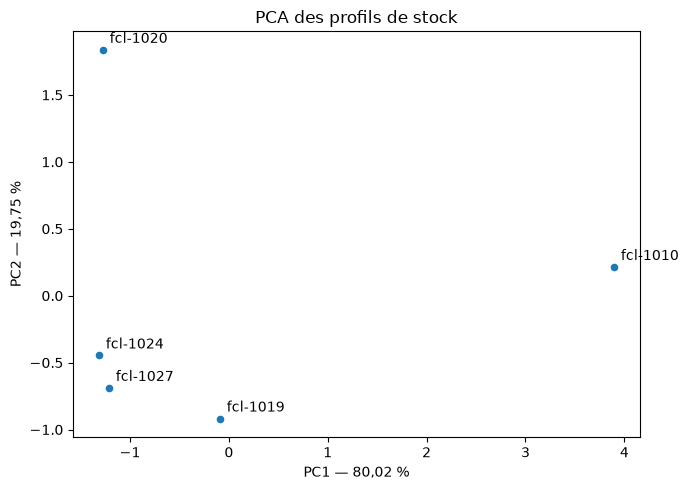

In [41]:
coordonnees.plot.scatter(x="PC1", y="PC2", figsize=(7, 5))

for site, ligne in coordonnees.iterrows():
    plt.annotate(
        site,
        (ligne["PC1"], ligne["PC2"]),
        xytext=(5, 5),
        textcoords="offset points"
    )

plt.xlabel("PC1 — 80,02 %")
plt.ylabel("PC2 — 19,75 %")
plt.title("PCA des profils de stock")
plt.tight_layout()
plt.show()

In [42]:
poids = pd.DataFrame(
    pca.components_.T,
    index=variables,
    columns=["PC1", "PC2"]
)

display(poids.round(2))

,PC1,PC2
received_quantity,0.50,0.01
outgoing_quantity,0.08,0.99
documented_internal_use,0.50,-0.07
documented_waste,0.50,-0.01
closing_stock,0.50,-0.08


La PCA distingue principalement un niveau conjoint de réceptions, d’usage interne, de déchets et de stock final, puis le niveau des sorties. Le site fcl-1010 se distingue sur la première dimension et fcl-1020 sur la seconde. Les sites fcl-1024 et fcl-1027 présentent des profils proches. Les deux axes expliquent ensemble 99,77 % de la variance des cinq profils étudiés.

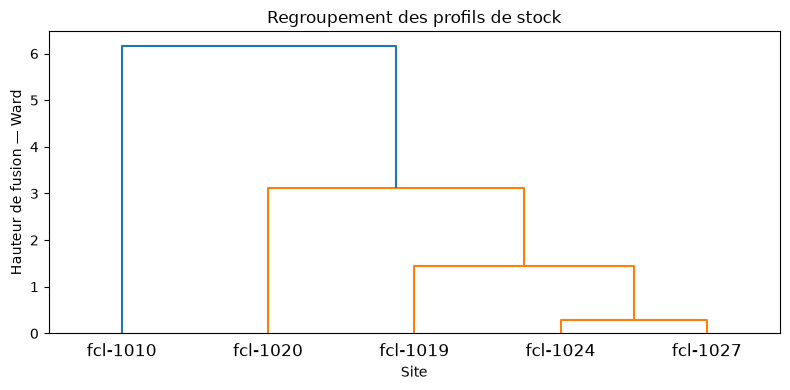

In [43]:
from scipy.cluster.hierarchy import linkage, dendrogram

liaisons = linkage(profils_standardises, method="ward")

plt.figure(figsize=(8, 4))
dendrogram(
    liaisons,
    labels=profils_standardises.index.tolist()
)

plt.title("Regroupement des profils de stock")
plt.xlabel("Site")
plt.ylabel("Hauteur de fusion — Ward")
plt.tight_layout()
plt.show()

La classification hiérarchique rapproche d’abord fcl-1024 et fcl-1027. Une coupe avant la dernière fusion distingue fcl-1010 des quatre autres sites, principalement en raison de ses niveaux élevés sur plusieurs variables de stock. Cette séparation décrit une différence de profil ; elle ne démontre pas une anomalie. Avec cinq sites, le regroupement reste exploratoire.

In [44]:
from scipy.cluster.hierarchy import fcluster

resultats = profils_sites.copy()
resultats["groupe"] = fcluster(
    liaisons, t=2, criterion="maxclust"
)

display(resultats.round(2))


,received_quantity,outgoing_quantity,documented_internal_use,documented_waste,closing_stock,groupe
facility_code,,,,,,
fcl-1010,33.23,2.94,14.07,4.32,167.62,2
fcl-1019,9.06,1.70,4.67,1.71,71.07,1
fcl-1020,3.25,3.99,1.46,0.76,21.09,1
fcl-1024,3.86,2.02,2.16,0.68,28.41,1
fcl-1027,3.76,1.81,2.83,0.82,28.59,1
